# Tutorial 04: spins (aligned)

With spins switched on, FastOmega differs from the first three chapters in only a few places (flowchart `pipeline_spin_steps.png`):

| Section | Source | Change |
|---|---|---|
| 1 | `_draw_spins` | each $q$ node gets $n_{\rm spin}=128$ scrambled Sobol spin samples, magnitudes drawn from the spin proposal |
| 2 | `_table_column` | the table columns go from $s$ to $(s,i)$: $121\times128=15488$ columns |
| 3 | SVD block of `__init__` | an extra $1/n_{\rm spin}$ in the column weights; still one SVD |
| 4 | `_spin_coefficients` | **every call**: importance weights → spin-averaged coefficients $\bar C_{rs}$ per $q$ node |
| 5 | `omega()` | otherwise unchanged |

Notation: $s$ = $q$ node, $i$ = spin sample, $r$ = SVD mode; a spin sample is $\boldsymbol\chi_{si}=(a_1,a_2,\cos\theta_1,\cos\theta_2)$.

In [1]:
import os
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[k] = "1"

In [2]:
%matplotlib inline
import sys
sys.path.append("../")
FIGDIR = "../../Figures/"

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='ticks', context='notebook', font='serif', 
        font_scale=1.5, palette='deep')
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amssymb}\usepackage{mathrsfs}\usepackage{bm}", 
    "font.family": "serif",
    'backend': 'pdf',
    # Grid
    "axes.grid": True,
    "grid.alpha": 0.7,
    "grid.linewidth": 0.4,

    # Ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    # Font
    'font.size': 18,
    'legend.fontsize': 18,
})
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from scipy.stats import qmc

from stochaxtic import jax_populations as jp
from stochaxtic.fast_omega import FastOmega, T_SUN, A_PRE, _fix_signs
from stochaxtic.constants import H0_SI

def check(name, mine, ref):
    mine, ref = np.asarray(mine), np.asarray(ref)
    assert mine.shape == ref.shape, (name, mine.shape, ref.shape)
    rel = np.max(np.abs(mine - ref)) / np.max(np.abs(ref))
    print(f"{name:30s} shape {str(ref.shape):18s} max |diff| / max |ref| = {rel:.1e}")
    return rel

fo = FastOmega(spins="aligned")              # table cached: 121 q nodes x 128 spin samples
n_q, n_s = fo.info["n_q"], fo.info["n_spin"]
a_max, seed = fo.a_max, 0
fo.info["rank"], fo._spin_samples.shape, fo.spin_proposal

FastOmega: SVD loaded from /home/haowen.zhong/.cache/stochaxtic/svd_IMRPhenomXAS_97b5bacfe2ddc071.npz
FastOmega: IMRPhenomXAS, spins=aligned, tides=False: 15488 table columns, rank 31; grids lnM 1231, z 444, lnq 121, lnf 1061; setup 0.1 s


(31, (121, 128, 6), 'defensive_gwtc5_wide')

## 1. Spin samples: an independently scrambled Sobol set per $q$ node

For each $q$ node $s$:
1. generate scrambled Sobol points $\mathbf u_{si}\in[0,1)^4$ with the seed `(seed, s)` (4-d for aligned spins; 6-d for precessing spins, with the in-plane azimuths $\phi_1$ and $\phi_{12}$);
2. clip them to $[10^{-9},1-10^{-9}]$, so that no density is evaluated on the boundary (a Beta density may diverge at 0 or 1);
3. map the tilts linearly, $\cos\theta=2u-1$ (isotropic), and the magnitudes through the inverse CDF of the **spin proposal** $g_a$ of $x=a/a_{\max}$, $a=a_{\max}G_a^{-1}(u)$.

The default proposal (`spin_proposal="auto"`) is, for $a_{\max}\geq0.5$ (BBH), the defensive mixture `defensive_gwtc5_wide`,
$$g_a(x)=\alpha+(1-\alpha)\,\mathcal N_{[0,1]}(x;\,0.15,\,0.45),\qquad\alpha=0.3,$$
shaped like the GWTC-5 spin magnitudes; the uniform part bounds the importance weights by $1/\alpha$ for any population. For $a_{\max}<0.5$ (BNS) it is uniform, $g_a=1$. The proposal density of a sample is
$$g=\frac{g_a(a_1/a_{\max})\,g_a(a_2/a_{\max})}{4a_{\max}^2}.$$

**Independent scrambling per $q$ node**: the integration errors of different nodes are independent, so they average out in the sum over $q$ instead of adding up coherently.


In [5]:
from scipy.stats import truncnorm

alpha, mu0, sig0 = 0.3, 0.15, 0.45                          # defensive_gwtc5_wide
h = truncnorm((0 - mu0) / sig0, (1 - mu0) / sig0, loc=mu0, scale=sig0)
xg = np.linspace(0.0, 1.0, 40001)
G = alpha * xg + (1 - alpha) * h.cdf(xg)                   # CDF of g_a
icdf = lambda u: np.interp(u, G, xg)
g_a = lambda x: alpha + (1 - alpha) * h.pdf(x)

def my_draw_spins(n_q, n_s, seed, a_max):
    out = np.zeros((n_q, n_s, 6))
    for k in range(n_q):
        u = qmc.Sobol(4, scramble=True, seed=np.random.default_rng([seed, k])).random(n_s)
        u = np.clip(u, 1e-9, 1 - 1e-9)
        out[k, :, 0] = a_max * icdf(u[:, 0])    # a1
        out[k, :, 1] = a_max * icdf(u[:, 1])    # a2
        out[k, :, 2] = 2 * u[:, 2] - 1          # cos theta1
        out[k, :, 3] = 2 * u[:, 3] - 1          # cos theta2
        # out[k, :, 4:6] = (phi1, phi12) = 0 for aligned spins
    return out

samples = my_draw_spins(n_q, n_s, seed, a_max)
check("spin samples", samples, fo._spin_samples)


spin samples                   shape (121, 128, 6)      max |diff| / max |ref| = 0.0e+00


np.float64(0.0)

Look at the samples of two $q$ nodes, projected onto the $(a_1,\cos\theta_1)$ plane. In the uniform Sobol coordinates $(u_{a_1},u_{\cos\theta_1})$ the 128 points put **exactly one** point in each cell of an $8\times16$ grid (a property of $(t,m,s)$-nets); the inverse CDF of the proposal then moves them towards small $a_1$, where the GWTC-5 magnitudes concentrate. The two nodes have different points (independent scrambling).


points per 8 x 16 cell of $($u_{a_1}, \cos t_1)$: min 1.0  max 1.0
fraction of samples with $a_1 < 0.3$: 0.39 (uniform: 0.30)


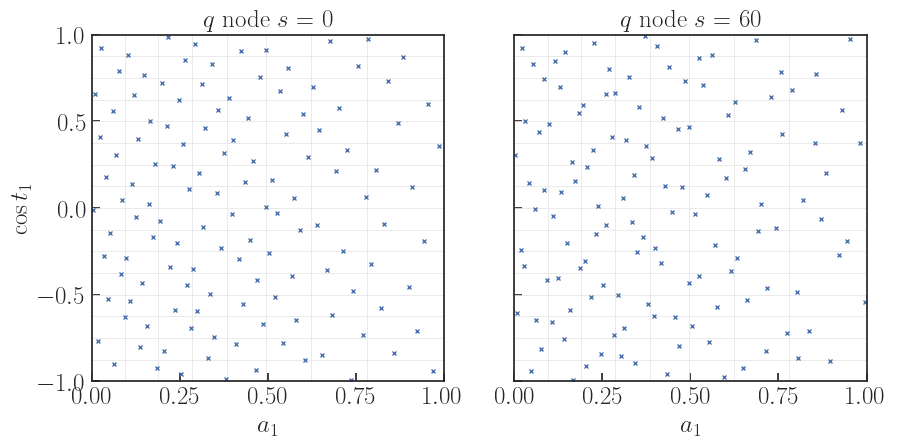

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for a, s in zip(ax, (0, 60)):
    for g in a_max * icdf(np.linspace(0, 1, 9)):          # the u_a1 columns, mapped to a_1
        a.axvline(g, color="0.9", lw=0.6)
    for g in np.linspace(-1, 1, 17):
        a.axhline(g, color="0.9", lw=0.6)
    a.plot(samples[s, :, 0], samples[s, :, 2], "x", ms=3)
    a.set(xlabel=r"$a_1$", title=rf"$q$ node $s$ = {s}")
ax[0].set_ylabel(r"$\cos t_1$");
ax[0].grid(visible=None)
ax[1].grid(visible=None)
ax[0].set_xlim(0,1)
ax[0].set_ylim(-1, 1)

ax[1].set_xlim(0,1)
ax[1].set_ylim(-1, 1)
u_a = np.interp(samples[0, :, 0] / a_max, xg, G)          # back to the uniform Sobol coordinate
H, _, _ = np.histogram2d(u_a, samples[0, :, 2], bins=[8, 16], range=[[0, 1], [-1, 1]])
print(r"points per 8 x 16 cell of $($u_{a_1}, \cos t_1)$: min", H.min(), " max", H.max())
print("fraction of samples with $a_1 < 0.3$:", np.mean(samples[..., 0] < 0.3).round(2), "(uniform: 0.30)")

## 2. A column with spins

The only difference from chapter 01: the spin vectors are passed to LAL. An aligned-spin model keeps only the projection on $\hat{\mathbf L}$, $\chi_{iz}=a_i\cos t_i$, and drops the in-plane components (`r1 = r2 = 0` in `_table_column` when `aligned`).

The cached table has shape `(n_q, n_kappa, n_spin, n_xJ)`; column $(s,i)$ is `J[s, 0, i]`.

In [9]:
from stochaxtic.orientation import OrientationAverager
J_cached = fo.table()[:, :, 0]
print("cached table:", J_cached.shape)

avg = OrientationAverager("IMRPhenomXAS")
m_ref, x_ref = fo.info["m_ref"], fo.info["x_ref"]
xJ = np.exp(fo.ln_xJ); live = xJ < 1.0

def my_column(s, i):
    q = min(np.exp(fo.lq[s]), 1.0 - 1e-6)
    m1, m2 = m_ref / (1 + q), m_ref * q / (1 + q)
    a1, a2, c1, c2, _, _ = samples[s, i]
    col = np.zeros(len(xJ))
    col[live] = avg(xJ[live] / (m_ref * T_SUN), m1, m2, (0, 0, a1 * c1), (0, 0, a2 * c2),
                    f_ref=x_ref / (m_ref * T_SUN)) / m_ref ** 4
    return col

for s, i in ((0, 0), (60, 17), (120, 127)):
    check(f"J column (s={s}, i={i})", my_column(s, i), J_cached[s, 0, i])

cached table: (121, 1, 128, 1007)
J column (s=0, i=0)            shape (1007,)            max |diff| / max |ref| = 0.0e+00
J column (s=60, i=17)          shape (1007,)            max |diff| / max |ref| = 0.0e+00
J column (s=120, i=127)        shape (1007,)            max |diff| / max |ref| = 0.0e+00


What do the columns for different spins at the same $q$ look like? Systems with larger $\chi_{\rm eff}$ merge later (at larger $x$) and radiate more. This is how spins change $\Omega$.

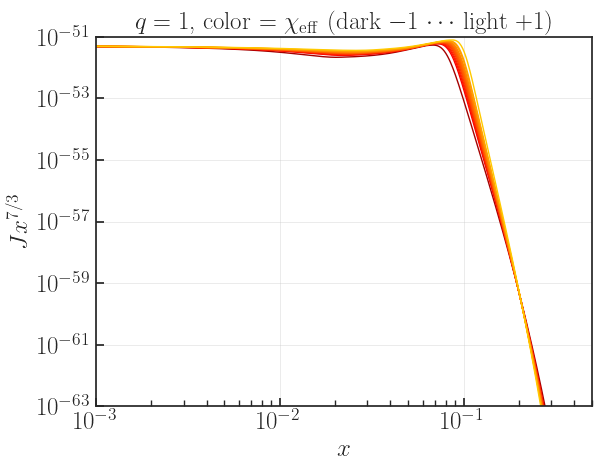

In [10]:
s = 120
chi_eff = (samples[s, :, 0] * samples[s, :, 2] + samples[s, :, 1] * samples[s, :, 3]) / 2      # q = 1
order = np.argsort(chi_eff)
cmap = plt.get_cmap("hot")
for i in order[::8]:
    J = J_cached[s, 0, i]; ok = J > 0
    plt.loglog(xJ[ok], J[ok] * xJ[ok] ** (7 / 3), color=cmap((chi_eff[i] + 1) / 2), lw=1)
plt.xlim(1e-3, 0.5); plt.ylim(1e-63, 1e-51)
plt.xlabel(r"$x$"); 
plt.ylabel(r"$J x^{7/3}$"); 
plt.title(r"$q = 1$, color = $\chi_{\rm eff}$ (dark $-1$ $\cdots$ light $+1$)");

## 3. SVD: one decomposition, an extra $1/n_{\rm spin}$ in the column weights

The matrix is now $1007\times15488$. The column weights are $c_{si}=\sqrt{w_s/n_{\rm spin}}$: each spin sample stands for $1/n_{\rm spin}$ of its $q$ node. **All columns go into one SVD**, which gives one common basis $B_{tr}$. This is what makes the "average over the coefficients" of section 4 possible.

(This SVD takes a few seconds.)

In [11]:
A = J_cached.reshape(-1, len(fo.ln_xJ)).T                         # columns ordered (s, kappa, i)
sx = np.sqrt(np.mean(A ** 2, axis=1))
An = np.where(sx[:, None] > 0, A / np.where(sx > 0, sx, 1.0)[:, None], 0.0)
colw = np.sqrt(np.repeat(fo.wq, 1 * n_s) / n_s)
u, sv, vt = np.linalg.svd(An * colw[None, :], full_matrices=False)
rank = int(min(96, max(1, np.sum(sv / sv[0] > 1e-4))))
_, vt_r = _fix_signs(u[:, :rank] * sv[:rank], vt[:rank])         # FastOmega's sign convention
coef = (vt_r / colw[None, :]).reshape(rank, n_q, 1, n_s)
print("rank =", rank, "(fo:", fo.info["rank"], ")  -- 8 without spins")
check("coef  ->  fo._C", coef, fo._C)

rank = 31 (fo: 31 )  -- 8 without spins
coef  ->  fo._C                shape (31, 121, 1, 128)  max |diff| / max |ref| = 1.5e-12


np.float64(1.4813040340300267e-12)

The rank grows from 8 without spins to 31: spins make the columns more diverse (the merger moves with $\chi_{\rm eff}$), and more modes are needed to describe them.

## 4. Every call: importance weights and spin-averaged coefficients

For given spin hyperparameters $\boldsymbol\theta_\chi$ (from here on the GWTC-5 population `gwtc5_default`, FastOmega's default spin model: truncated-normal magnitudes; tilts a mixture of an isotropic part and a truncated normal in $\cos\theta$ around $\mu_t$):
$$\omega_{si}=\frac{p(\boldsymbol\chi_{si}\,|\,\boldsymbol\theta_\chi)}{g},\qquad
\bar C_{rs}=\frac{\sum_i\omega_{si}\,C_{r,(si)}}{\sum_i\omega_{si}}.$$

- The density is evaluated in $(a,\cos\theta)$, not in $\chi_z$: that is how the population models are defined.
- **Self-normalised** (divided by $\sum_i\omega_{si}$): even if $p$ does not integrate exactly to 1 over the box (e.g. the part with $a>a_{\max}$ is cut off), the weights of each $q$ node still sum to 1. Constant factors (the $1/4a_{\max}^2$ of $g$) cancel; the shape of $g$ does not: with the defensive proposal every sample carries its own $g$.
- The average is taken over the **coefficients**: $\bar J_{ts}=\sum_i\bar\omega_{si}J_{t,(si)}\approx\sum_rB_{tr}\bar C_{rs}$. The basis $B$ and its FFT do not depend on $\boldsymbol\theta_\chi$ and are not recomputed.

In [13]:
fn, sp_default = jp.SPIN_MODELS["gwtc5_default"]
print("gwtc5_default defaults:", sp_default)
a1, a2, c1, c2 = (jnp.asarray(samples[..., k]) for k in range(4))
g = jnp.asarray(g_a(samples[..., 0] / a_max) * g_a(samples[..., 1] / a_max) / (4.0 * a_max ** 2))
check("g  ->  _g_spin", g, fo._g_spin)

def my_spin_coefficients(sp):
    w = fn(a1, a2, c1, c2, sp, a_max) / g                                   # (n_q, n_s)
    return jnp.einsum("rkts,ks->rkt", fo._C, w) / jnp.sum(w, axis=1)[None, :, None], w

Cbar, w = my_spin_coefficients(sp_default)
check("Cbar  ->  _spin_coefficients", Cbar, fo._spin_coefficients("gwtc5_default", sp_default))
print("Cbar:", Cbar.shape, "  (rank, n_q, n_t)")

gwtc5_default defaults: {'mu_chi': 0.0633, 'sigma_chi': 0.365, 'chi_max': 1.0, 'mu_t': 0.319, 'sigma_t': 1.11, 'zeta': 0.671}
g  ->  _g_spin                 shape (121, 128)         max |diff| / max |ref| = 0.0e+00
Cbar  ->  _spin_coefficients   shape (31, 121, 1)       max |diff| / max |ref| = 7.2e-16
Cbar: (31, 121, 1)   (rank, n_q, n_t)


### Effective sample size (ESS)

The quality of self-normalised importance sampling is measured by $\mathrm{ESS}=(\sum_i\omega_i)^2/\sum_i\omega_i^2$. The more concentrated the weights, the smaller the ESS, and the more the average rests on a few samples. The narrower the population and the further it is from the proposal, the lower the ESS (QMC does not help here). This is why the default proposal for BBH follows the GWTC-5 magnitudes: with a uniform proposal the ESS of `gwtc5_default` is 60 of 128, with `defensive_gwtc5_wide` 91, and the spin Monte Carlo error of $\Omega$ halves (`examples/spin_proposal_test.py`).

`fo.check_spins(spin_model, spin_params)` computes the same ESS per $q$ node and warns when its median drops below `min_ess` (default 10); `make()` runs it on the default spin parameters. Run it yourself on the extremes of your prior.


In [14]:
def ess(sp, model="gwtc5_default"):
    f, d = jp.SPIN_MODELS[model]
    ww = np.asarray(f(a1, a2, c1, c2, {**d, **sp}, a_max) / g)
    return np.mean(ww.sum(1) ** 2 / (ww ** 2).sum(1))

for lab, sp, model in (("gwtc5_default (defaults)", {}, "gwtc5_default"),
                       ("gwtc3_default (defaults)", {}, "gwtc3_default"),
                       ("gwtc5, sigma_chi = 0.1", {"sigma_chi": 0.1}, "gwtc5_default"),
                       ("gwtc5, sigma_chi = 0.05", {"sigma_chi": 0.05}, "gwtc5_default"),
                       ("gwtc5, zeta=1, sigma_t=0.1", {"zeta": 1.0, "sigma_t": 0.1, "mu_t": 1.0}, "gwtc5_default")):
    print(f"{lab:30s} ESS = {ess(sp, model):6.1f} / {n_s}")

# the built-in check: median and minimum over the q nodes, with a warning below min_ess
res = fo.check_spins("gwtc5_default", {"zeta": 1.0, "sigma_t": 0.1, "mu_t": 1.0}, warn=False)
print("check_spins:", {k: res[k] for k in ("ess_median", "ess_min", "n_spin")})

gwtc5_default (defaults)       ESS =   91.4 / 128
gwtc3_default (defaults)       ESS =   67.0 / 128
gwtc5, sigma_chi = 0.1         ESS =   12.1 / 128
gwtc5, sigma_chi = 0.05        ESS =    4.8 / 128
gwtc5, zeta=1, sigma_t=0.1     ESS =    1.5 / 128
check_spins: {'ess_median': 1.411098660655062, 'ess_min': 1.0116751952654381, 'n_spin': 128}


## 5. Everything else is unchanged

Wrap steps 4–9 of chapter 03 into a function (input $\hat P_{\ell r}$, output $\Omega$), then replace only the $C_{rs}$ of step 3 by $\bar C_{rs}$. `gwtc5_default` is the default `spin_model` of `omega()`, `make()` and `check_spins()`; the code below passes it explicitly only for clarity.

In [15]:
mass, rate = "bpl_double_gaussian", "madau_dickinson"
d = fo.info["delta"]

def P_cells(mp=None):                      # chapter 03, steps 1-2 (n_sub = 1 for this model)
    m1, m2, jac = fo._mass_grid(1)
    fnm, mdef = jp.MASS_MODELS[mass]
    P = fnm(m1, m2, {**mdef, **(mp or {}), "_w": d}) * jac
    P = P / jnp.sum(P * fo._cell)
    return P * fo._cell

def omega_from_Phat(P_hat, rp=None):       # chapter 03, steps 4-9
    w = fo._zw * jp.RATE_MODELS[rate](jnp.asarray(fo.z), {**jp.RATE_DEFAULTS[rate], **(rp or {})})
    K = jnp.fft.irfft(jnp.fft.rfft(P_hat, n=fo._L1, axis=0) * jnp.fft.rfft(w, n=fo._L1)[:, None],
                      n=fo._L1, axis=0)[:fo._n_d] * fo._e4l
    c = jnp.fft.irfft(jnp.sum(jnp.fft.rfft(K[::-1], n=fo._L2, axis=0) * fo._FJ, axis=1), n=fo._L2)
    S = c[fo._n_d - 1:fo._n_d - 1 + fo._n_f]
    lnf = jnp.asarray(np.log(fo.freqs))
    S = jp.interp_uniform(lnf, fo.lnf[0], d, S)
    return S * jnp.exp(-A_PRE * (np.log(T_SUN) + lnf)) * 4 * np.pi ** 2 * jnp.exp(3 * lnf) / (3 * H0_SI ** 2)

P = P_cells()
Omega_mine = omega_from_Phat(P @ Cbar[:, :, 0].T)          # the ONLY spin-specific line
check("Omega with spins", Omega_mine, fo.omega(mass, rate, spin_model="gwtc5_default"))

Omega with spins               shape (996,)             max |diff| / max |ref| = 3.9e-15


np.float64(3.889302745261594e-15)

## 6. Exercise: how spins change $\Omega$

Compare with `gwtc5_default`: no spins (the table of chapters 01–03, on the same grids), the GWTC-3 population `gwtc3_default`, and large spins ($\mu_\chi=0.5$, $\sigma_\chi=0.3$) that are either isotropic ($\zeta=0$) or nearly aligned ($\zeta=1$, $\mu_t=1$, $\sigma_t=0.3$). An aligned-spin waveform responds to $\chi_{\rm eff}$: aligned spins delay the merger and raise $\Omega$, more and more towards high frequency, while isotropic tilts largely cancel ($\chi_{\rm eff}\approx0$ on average) below a few hundred Hz. The aligned case is far from the proposal (ESS ≈ 7, `check_spins` would warn): good enough for this picture, not for inference.

median ESS of the large aligned case: 7.2 / 128


(5, 1000)

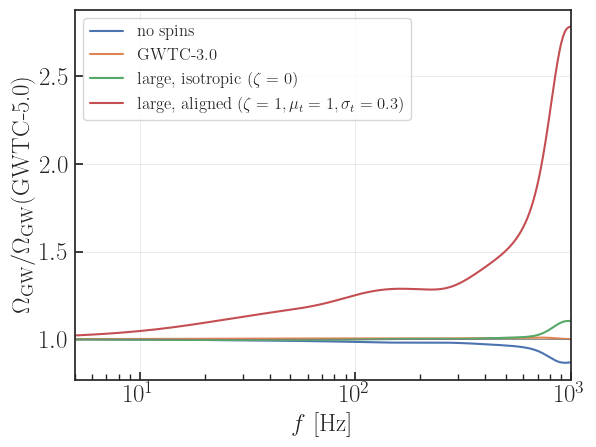

In [16]:
om = fo.make(mass, rate, spin_model="gwtc5_default")
base = om()
fo0 = FastOmega(verbose=False)                   # no spins: the table of chapters 01-03, same grids
big = {"mu_chi": 0.5, "sigma_chi": 0.3}
aligned = {**big, "zeta": 1.0, "mu_t": 1.0, "sigma_t": 0.3}
curves = {"no spins": fo0.omega(mass, rate),
          "GWTC-3.0": fo.omega(mass, rate, spin_model="gwtc3_default"),
          r"large, isotropic $(\zeta = 0)$": om(None, None, {**big, "zeta": 0.0}),
          r"large, aligned $(\zeta = 1, \mu_t = 1, \sigma_t = 0.3)$": om(None, None, aligned)}
for lab, O in curves.items():
    plt.semilogx(fo.freqs, np.asarray(O / base), label=lab)
plt.axhline(1, color="0.5", lw=0.6)
plt.xlabel(r"$f$ [Hz]") 
plt.ylabel(r"$\Omega_{\rm GW} / \Omega_{\rm GW}$(GWTC-5.0)") 
plt.legend(fontsize=12)
print("median ESS of the large aligned case:",
      round(fo.check_spins("gwtc5_default", aligned, warn=False)["ess_median"], 1), "/", n_s)
plt.xlim(5, 1000)

## Summary

| Quantity | No spins | Aligned spins |
|---|---|---|
| table columns | 121 | 121 × 128 = 15488 |
| column weights | $\sqrt{w_s}$ | $\sqrt{w_s/n_{\rm spin}}$ |
| proposal density | — | $g=g_a(a_1)g_a(a_2)/4a_{\max}^2$ per sample |
| rank $R$ | 8 | 31 |
| `fo._C` | (8, 121, 1, 1) | (31, 121, 1, 128) |
| extra steps per call | — | $\omega_{si}$ and $\bar C_{rs}$ (arrays 121×128 and 31×121) |

The spin hyperparameters enter **only** through $\omega_{si}$, so changing the spin population costs almost nothing. The accuracy is set by the 128 QMC points per $q$ node (measured error $\propto n_{\rm spin}^{-1.1\ldots-1.2}$), and for narrow populations it is limited by the ESS (see `check_spins`).

**Next chapter (05)**: tides. The columns become $(s,c)$ ($c$ = $\kappa_2^T$ node), and every call gets an extra weight $W_{\ell sc}$ that depends on the source-frame mass and must be contracted before the redshift convolution.